In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print('TensorFlow version:', tf.__version__)
print('Available GPUs:', tf.config.list_physical_devices('GPU'))

/Users/saugat/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow version: 2.20.0
Available GPUs: []


In [2]:
(X_train_raw, y_train_raw), (X_test_raw, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print('Original training images:', X_train_raw.shape)
print('Test images:', X_test_raw.shape)
print('Labels:', class_names)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original training images: (60000, 28, 28)
Test images: (10000, 28, 28)
Labels: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [3]:
(X_train_raw, y_train_raw), (X_test_raw, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print('Original training images:', X_train_raw.shape)
print('Test images:', X_test_raw.shape)
print('Labels:', class_names)


Original training images: (60000, 28, 28)
Test images: (10000, 28, 28)
Labels: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


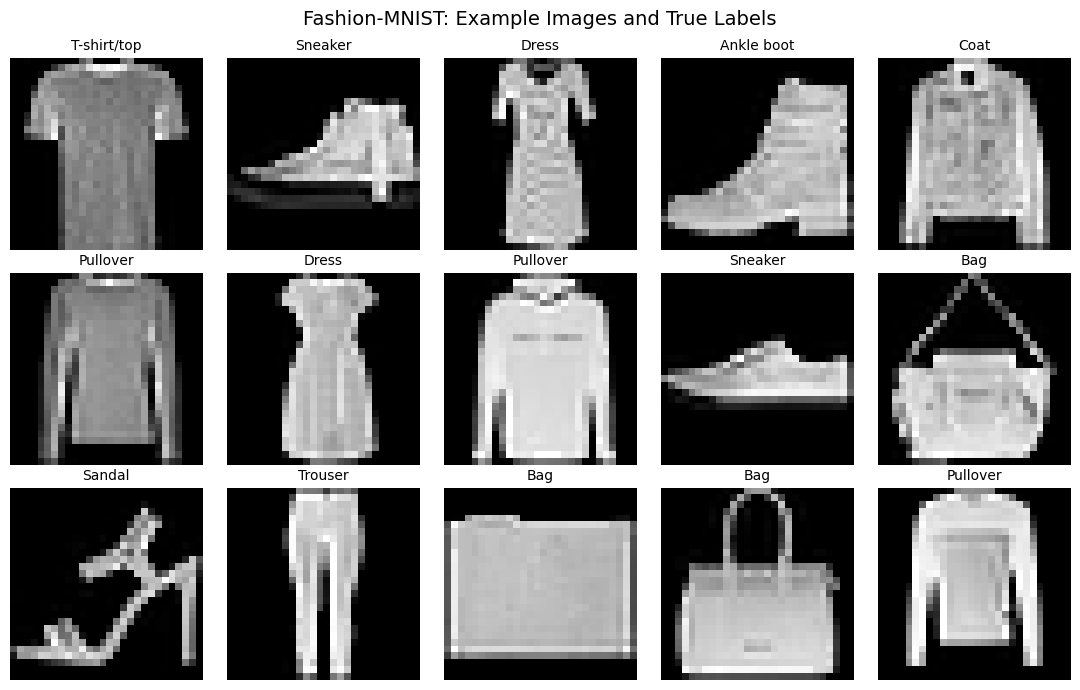

In [4]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_train_raw), size=15, replace=False)

fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(X_train_raw[idx], cmap='gray')
    ax.set_title(class_names[y_train_raw[idx]], fontsize=10)
    ax.axis('off')
plt.suptitle('Fashion-MNIST: Example Images and True Labels', fontsize=14)
plt.tight_layout()
plt.show()

In [5]:
X_all = (X_train_raw.astype('float32') / 255.0)[..., np.newaxis]
X_test = (X_test_raw.astype('float32') / 255.0)[..., np.newaxis]

X_train, X_val, y_train, y_val = train_test_split(
    X_all,
    y_train_raw,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train_raw
)

print('Training images:', X_train.shape)
print('Validation images:', X_val.shape)
print('Held-out test images:', X_test.shape)
print('Pixel range:', X_train.min(), 'to', X_train.max())

Training images: (54000, 28, 28, 1)
Validation images: (6000, 28, 28, 1)
Held-out test images: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0


In [6]:
MAX_EPOCHS = 27
BATCH_SIZE = 128

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    # Mild augmentation is active during training only.
    layers.RandomTranslation(0.05, 0.05, fill_mode='nearest'),
    layers.RandomRotation(0.03, fill_mode='nearest'),

    layers.Conv2D(40, kernel_size=3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(56, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.18),

    layers.Conv2D(88, kernel_size=3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(120, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.30),

    layers.Conv2D(144, kernel_size=3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Flatten(),
    layers.Dense(176, activation='relu'),
    layers.Dropout(0.38),
    layers.Dense(10, activation='softmax')
], name='fashion_mnist_custom_cnn')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "fashion_mnist_custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 40)     │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 40)     │           160 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 56)     │        20,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 56)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 56)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 88)     │        44,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 88)     │           352 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 120)    │        95,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 120)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 120)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 144)      │       155,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 144)      │           576 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7056)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 176)            │     1,242,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 176)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,770 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,560,770 (5.95 MB)

 Trainable params: 1,560,226 (5.95 MB)

 Non-trainable params: 544 (2.12 KB)

In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f'Completed epochs: {len(history.history["loss"])} / {MAX_EPOCHS}')
print(f'Best validation-loss epoch: {best_epoch}')
print(f'Best validation accuracy observed: {max(history.history["val_accuracy"]):.2%}')

Epoch 1/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 101ms/step - accuracy: 0.7122 - loss: 0.8203 - val_accuracy: 0.7238 - val_loss: 0.8518 - learning_rate: 0.0010
Epoch 2/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - accuracy: 0.8398 - loss: 0.4375 - val_accuracy: 0.8747 - val_loss: 0.3494 - learning_rate: 0.0010
Epoch 3/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 112ms/step - accuracy: 0.8690 - loss: 0.3608 - val_accuracy: 0.8887 - val_loss: 0.2960 - learning_rate: 0.0010
Epoch 4/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 112ms/step - accuracy: 0.8770 - loss: 0.3273 - val_accuracy: 0.8668 - val_loss: 0.3532 - learning_rate: 0.0010
Epoch 5/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 114ms/step - accuracy: 0.8842 - loss: 0.3113 - val_accuracy: 0.9093 - val_loss: 0.2500 - learning_rate: 0.0010
Epoch 6/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 50s 118ms/step - accuracy: 0.8917 - loss: 0.2903 - val_accuracy: 0.9138 - val_loss: 0.2375 - learning_rate: 0.0010
Epoch 7/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 52s 123ms/step - accuracy: 0.8

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f'Completed epochs: {len(history.history["loss"])} / {MAX_EPOCHS}')
print(f'Best validation-loss epoch: {best_epoch}')
print(f'Best validation accuracy observed: {max(history.history["val_accuracy"]):.2%}')

Epoch 1/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 101ms/step - accuracy: 0.9462 - loss: 0.1427 - val_accuracy: 0.9453 - val_loss: 0.1612 - learning_rate: 2.5000e-04
Epoch 2/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 108ms/step - accuracy: 0.9476 - loss: 0.1433 - val_accuracy: 0.9477 - val_loss: 0.1616 - learning_rate: 2.5000e-04
Epoch 3/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 112ms/step - accuracy: 0.9489 - loss: 0.1368 - val_accuracy: 0.9480 - val_loss: 0.1596 - learning_rate: 2.5000e-04
Epoch 4/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 50s 118ms/step - accuracy: 0.9479 - loss: 0.1407 - val_accuracy: 0.9462 - val_loss: 0.1638 - learning_rate: 2.5000e-04
Epoch 5/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 52s 124ms/step - accuracy: 0.9499 - loss: 0.1337 - val_accuracy: 0.9500 - val_loss: 0.1602 - learning_rate: 2.5000e-04
Epoch 6/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 53s 126ms/step - accuracy: 0.9497 - loss: 0.1335 - val_accuracy: 0.9465 - val_loss: 0.1619 - learning_rate: 2.5000e-04
Epoch 7/27
422/422 ━━━━━━━━━━━━━━━━━━━━ 54s 12

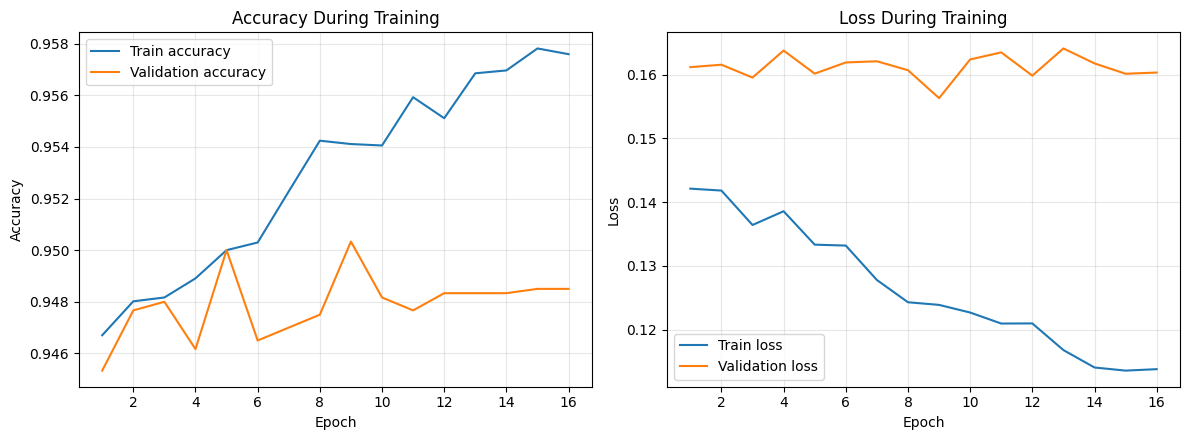

In [9]:
epochs_seen = np.arange(1, len(history.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epochs_seen, history.history['accuracy'], label='Train accuracy')
axes[0].plot(epochs_seen, history.history['val_accuracy'], label='Validation accuracy')
axes[0].set(title='Accuracy During Training', xlabel='Epoch', ylabel='Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_seen, history.history['loss'], label='Train loss')
axes[1].plot(epochs_seen, history.history['val_loss'], label='Validation loss')
axes[1].set(title='Loss During Training', xlabel='Epoch', ylabel='Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'TEST ACCURACY: {test_accuracy:.2%}')
print(f'Correct test images (out of 10,000): approximately {round(test_accuracy * len(y_test)):,}')

Test loss: 0.1841
TEST ACCURACY: 94.19%
Correct test images (out of 10,000): approximately 9,419


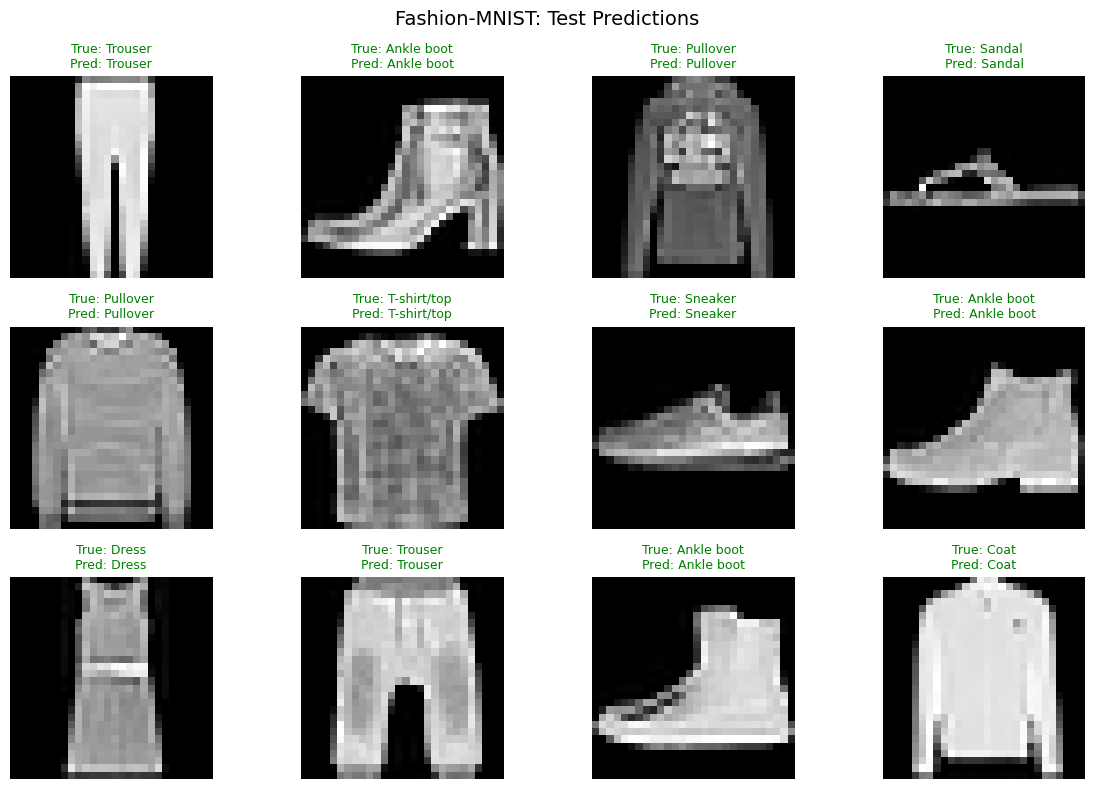

In [11]:
y_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

indices = np.random.default_rng(123).choice(len(X_test), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for ax, i in zip(axes.flat, indices):
    correct = y_pred[i] == y_test[i]
    ax.imshow(X_test[i, :, :, 0], cmap='gray')
    ax.set_title(
        f'True: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]}',
        fontsize=9,
        color='green' if correct else 'red'
    )
    ax.axis('off')
plt.suptitle('Fashion-MNIST: Test Predictions', fontsize=14)
plt.tight_layout()
plt.show()

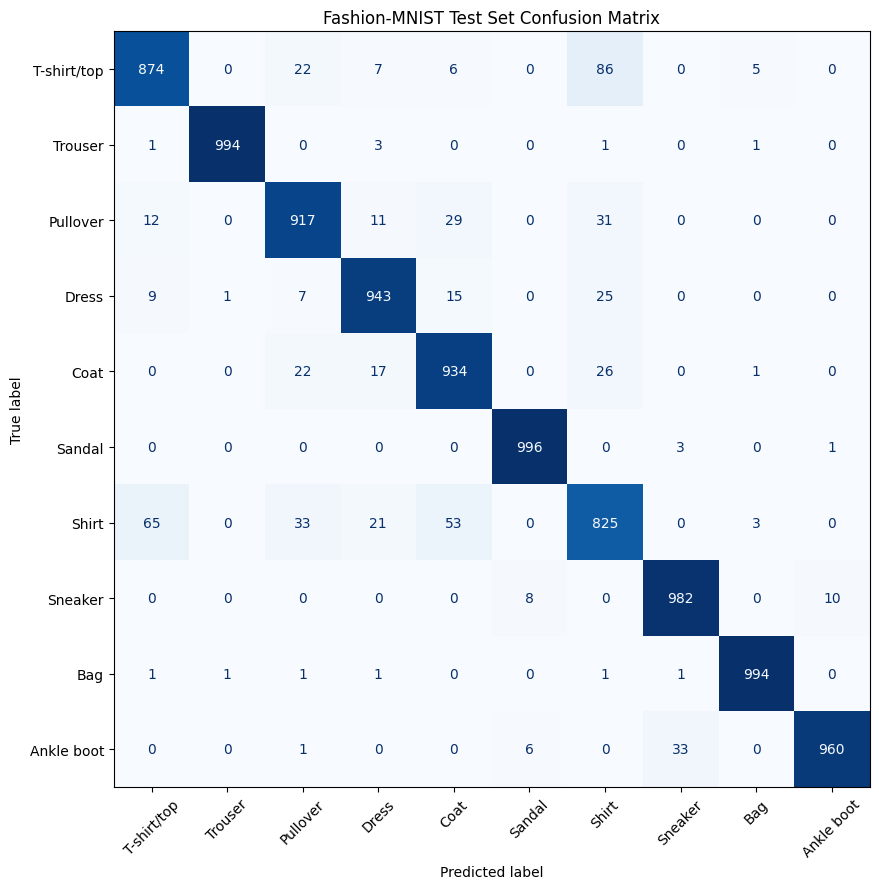

In [12]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(9.5, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False, values_format='d')
ax.set_title('Fashion-MNIST Test Set Confusion Matrix')
plt.tight_layout()
plt.show()


FASHION-MNIST — FINAL HELD-OUT TEST RESULTS
Model: Custom 5-convolution CNN + batch normalization + dropout
Maximum epochs configured: 27
Epochs actually completed: 16
TEST ACCURACY: 94.19%
Requirement (>91.5%): PASSED
Extra credit (>92.0%): PASSED


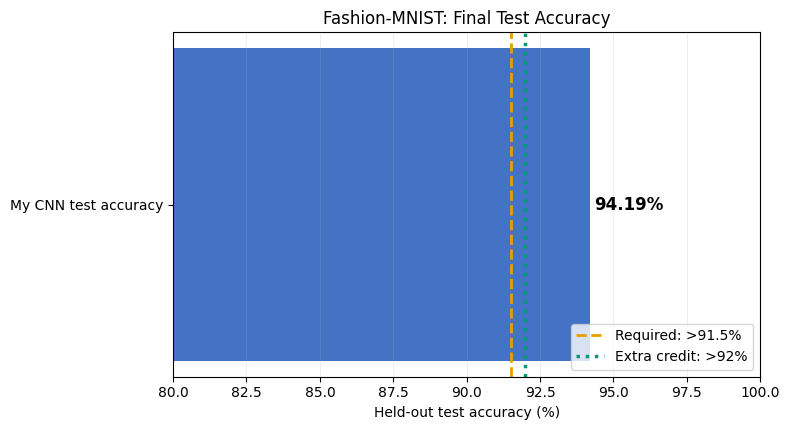

In [ ]:
required = 0.915
extra_credit = 0.92

print('=' * 58)
print('FASHION-MNIST — FINAL HELD-OUT TEST RESULTS')
print('=' * 58)
print('Model: Custom 5-convolution CNN + batch normalization + dropout')
print(f'Maximum epochs configured: {MAX_EPOCHS}')
print(f'Epochs actually completed: {len(history.history["loss"])}')
print(f'TEST ACCURACY: {test_accuracy:.2%}')

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(['My CNN test accuracy'], [test_accuracy * 100], height=0.42, color='#4472C4')
ax.axvline(91.5, color='#E69F00', linestyle='--', linewidth=2, label='Required: >91.5%')
ax.axvline(92.0, color='#009E73', linestyle=':', linewidth=2.5, label='Extra credit: >92%')
ax.text(min(test_accuracy * 100 + 0.15, 98), 0, f'{test_accuracy:.2%}', va='center', fontsize=12, fontweight='bold')
ax.set_xlim(80, 100)
ax.set_xlabel('Held-out test accuracy (%)')
ax.set_title('Fashion-MNIST: Final Test Accuracy')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()